# OSCC GraphRAG — Phase 3: EfficientNetB0 + Hybrid Retrieval

This notebook integrates the **existing EfficientNetB0 classifier** with the Phase 2 GraphRAG pipeline.

**Existing CNN is not modified.**

Flow:

`Image → Existing EfficientNetB0 → OSCC/Normal + confidence → Neo4j + FAISS → evidence/context`

> Research-use note: the retrieved literature is contextual evidence. It does **not** establish that a particular histological feature or biomarker is present in the input image, and the output is not a clinical diagnosis.


In [ ]:
# 1. Install dependencies
!pip -q install tensorflow sentence-transformers faiss-cpu neo4j requests beautifulsoup4 lxml


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 48.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.5/331.5 kB 18.3 MB/s eta 0:00:00


In [ ]:
# 2. Imports and Google Drive
import os
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing import image
from google.colab import userdata, drive

drive.mount("/content/drive")

print("TensorFlow:", tf.__version__)


Mounted at /content/drive
TensorFlow: 2.20.0


In [ ]:
# 3. Load existing Neo4j credentials from Colab Secrets
NEO4J_URI = userdata.get("NEO4J_URI")
NEO4J_USERNAME = userdata.get("NEO4J_USERNAME")
NEO4J_PASSWORD = userdata.get("NEO4J_PASSWORD")
NEO4J_DATABASE = userdata.get("NEO4J_DATABASE")

required = {
    "NEO4J_URI": NEO4J_URI,
    "NEO4J_USERNAME": NEO4J_USERNAME,
    "NEO4J_PASSWORD": NEO4J_PASSWORD,
    "NEO4J_DATABASE": NEO4J_DATABASE,
}
missing = [k for k, v in required.items() if not v]
if missing:
    raise ValueError(f"Missing Colab Secrets: {missing}")

print("Neo4j secrets loaded successfully.")
print("Database:", NEO4J_DATABASE)


Neo4j secrets loaded successfully.
Database: 304dd69f


In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Final Year Project/oral_cancer_efficientnetb0.keras"

import os

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

print("CNN model found:")
print(MODEL_PATH)

CNN model found:
/content/drive/MyDrive/Final Year Project/oral_cancer_efficientnetb0.keras


In [ ]:
# 5. Load the EXISTING EfficientNetB0 model
# This is the same model-loading approach as your current CNN code.
model = tf.keras.models.load_model(MODEL_PATH)

print("Existing EfficientNetB0 model loaded.")


Existing EfficientNetB0 model loaded.


In [ ]:
# 6. CNN prediction function
# The model architecture/training is NOT changed.

def predict_oscc(image_path):
    img = image.load_img(image_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    prediction = float(model.predict(img_array, verbose=0)[0][0])

    if prediction >= 0.5:
        label = "OSCC"
        confidence = prediction
    else:
        label = "Normal"
        confidence = 1.0 - prediction

    return {
        "label": label,
        "confidence": confidence,
        "raw_probability": prediction,
    }


In [ ]:
# 7. Test the existing CNN
# Change this path to the image you want to analyze.
IMAGE_PATH = "/Histologic-image-of-oral-squamous-cell-carcinoma-hematoxylin-eosin-stain-original.webp"

result = predict_oscc(IMAGE_PATH)

print(f"Prediction: {result['label']}")
print(f"Confidence: {result['confidence'] * 100:.2f}%")
print(f"Raw model probability: {result['raw_probability']:.6f}")


Prediction: OSCC
Confidence: 99.05%
Raw model probability: 0.990503


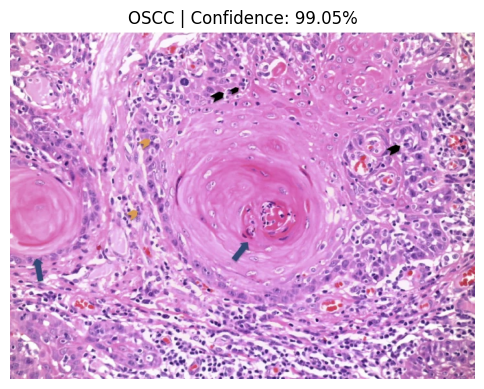

In [ ]:
# 8. Display the input image
img = plt.imread(IMAGE_PATH)
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(f"{result['label']} | Confidence: {result['confidence']*100:.2f}%")
plt.show()


In [ ]:
# 9. Load FAISS + metadata from Phase 2
import faiss
from sentence_transformers import SentenceTransformer

index = faiss.read_index(FAISS_PATH)

with open(METADATA_PATH, "r", encoding="utf-8") as f:
    chunk_metadata = json.load(f)

embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

print("FAISS index loaded.")
print("Metadata records:", len(chunk_metadata))
print("Vector count:", index.ntotal)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

FAISS index loaded.
Metadata records: 189
Vector count: 189


In [ ]:
# 10. Neo4j connection
from neo4j import GraphDatabase

driver = GraphDatabase.driver(
    NEO4J_URI,
    auth=(NEO4J_USERNAME, NEO4J_PASSWORD)
)

with driver.session(database=NEO4J_DATABASE) as session:
    value = session.run("RETURN 1 AS ok").single()["ok"]

print("Neo4j connection:", "OK" if value == 1 else "FAILED")


Neo4j connection: OK


In [ ]:
# 11. Graph retrieval
def get_oscc_graph_context():
    query = '''
    MATCH (d:Disease {name: "Oral Squamous Cell Carcinoma"})
    OPTIONAL MATCH (d)-[hf:HAS_HISTOLOGICAL_FEATURE]->(f:HistologicalFeature)
    OPTIONAL MATCH (d)-[bm:ASSOCIATED_WITH_BIOMARKER]->(b:Biomarker)
    OPTIONAL MATCH (d)-[rf:ASSOCIATED_WITH_RISK_FACTOR]->(r:RiskFactor)
    OPTIONAL MATCH (d)-[dm:EVALUATED_BY]->(m:DiagnosticMethod)
    OPTIONAL MATCH (p:ResearchPaper)-[rel:SUPPORTS]->(d)
    RETURN
        d.name AS disease,
        d.alias AS alias,
        collect(DISTINCT {
            name: f.name,
            provenance: hf.provenance
        }) AS histological_features,
        collect(DISTINCT {
            name: b.name,
            provenance: bm.provenance
        }) AS biomarkers,
        collect(DISTINCT {
            name: r.name,
            provenance: rf.provenance
        }) AS risk_factors,
        collect(DISTINCT {
            name: m.name,
            provenance: dm.provenance
        }) AS diagnostic_methods,
        collect(DISTINCT {
            paper_id: p.paper_id,
            title: p.title,
            year: p.year,
            provenance: rel.provenance
        }) AS supporting_papers
    '''

    with driver.session(database=NEO4J_DATABASE) as session:
        record = session.run(query).single()

    if record is None:
        return {}

    return dict(record)


In [ ]:
# 12. Vector retrieval
def vector_retrieve(query_text, top_k=5):
    query_embedding = embedder.encode(
        [query_text],
        normalize_embeddings=True
    ).astype("float32")

    scores, indices = index.search(query_embedding, top_k)

    results = []
    for score, idx in zip(scores[0], indices[0]):
        if idx < 0 or idx >= len(chunk_metadata):
            continue

        item = dict(chunk_metadata[idx])
        item["similarity"] = float(score)
        results.append(item)

    return results


In [ ]:
# 13. Hybrid retrieval
def hybrid_retrieve(prediction_label, confidence, top_k=5):
    # Query is based only on the classifier-level prediction.
    # It does not claim that image-specific microscopic features were detected.
    if prediction_label == "OSCC":
        query = (
            "oral squamous cell carcinoma histopathology "
            "diagnosis histological features biomarkers prognosis"
        )
    else:
        query = (
            "oral squamous cell carcinoma diagnosis "
            "normal oral epithelium histopathology differential diagnosis"
        )

    graph_context = get_oscc_graph_context()
    vector_context = vector_retrieve(query, top_k=top_k)

    return {
        "prediction": prediction_label,
        "confidence": float(confidence),
        "query": query,
        "graph_context": graph_context,
        "vector_context": vector_context,
        "scope_note": (
            "Research-use context only. Retrieved graph/literature associations "
            "are not image findings and do not constitute a clinical diagnosis."
        )
    }


In [ ]:
# 14. Run GraphRAG integration
graphrag_result = hybrid_retrieve(
    prediction_label=result["label"],
    confidence=result["confidence"],
    top_k=5
)

print("Prediction:", graphrag_result["prediction"])
print(f"Confidence: {graphrag_result['confidence'] * 100:.2f}%")
print()
print("GraphRAG retrieval completed.")
print("Vector evidence items:", len(graphrag_result["vector_context"]))


Prediction: OSCC
Confidence: 99.05%

GraphRAG retrieval completed.
Vector evidence items: 5


In [ ]:
# 15. Human-readable research report
def print_report(data):
    print("=" * 70)
    print("OSCC GRAPHRAG RESEARCH REPORT")
    print("=" * 70)

    print(f"Model prediction : {data['prediction']}")
    print(f"Confidence       : {data['confidence'] * 100:.2f}%")
    print()

    graph = data["graph_context"]

    if graph:
        print("KNOWLEDGE GRAPH CONTEXT")
        print("-" * 70)
        print("Disease:", graph.get("disease"))
        print("Alias:", graph.get("alias"))

        features = [
            x["name"] for x in graph.get("histological_features", [])
            if x.get("name")
        ]
        biomarkers = [
            x["name"] for x in graph.get("biomarkers", [])
            if x.get("name")
        ]
        risks = [
            x["name"] for x in graph.get("risk_factors", [])
            if x.get("name")
        ]

        print("Histological features in KG:", ", ".join(features))
        print("Biomarkers in KG:", ", ".join(biomarkers))
        print("Risk factors in KG:", ", ".join(risks))

    print()
    print("TOP LITERATURE EVIDENCE")
    print("-" * 70)

    for i, item in enumerate(data["vector_context"], 1):
        print(f"{i}. {item.get('title', 'Unknown title')}")
        print(f"   Paper ID   : {item.get('paper_id', 'N/A')}")
        print(f"   Year       : {item.get('year', 'N/A')}")
        print(f"   Similarity : {item.get('similarity', 0):.4f}")
        print(f"   Chunk      : {item.get('chunk_id', 'N/A')}")
        print()

    print("SCOPE NOTE")
    print("-" * 70)
    print(data["scope_note"])
    print("=" * 70)

print_report(graphrag_result)


OSCC GRAPHRAG RESEARCH REPORT
Model prediction : OSCC
Confidence       : 99.05%

KNOWLEDGE GRAPH CONTEXT
----------------------------------------------------------------------
Disease: Oral Squamous Cell Carcinoma
Alias: OSCC
Histological features in KG: Depth of invasion, Perineural invasion, Lymphovascular invasion, Tumor budding, Pattern of invasion
Biomarkers in KG: p16, PD-L1, EGFR, Cyclin D1, Ki-67
Risk factors in KG: Tobacco, Alcohol consumption

TOP LITERATURE EVIDENCE
----------------------------------------------------------------------
1. Immunohistochemical Markers in the Early Identification of Oral Squamous Cell Carcinoma: A Systematic Review
   Paper ID   : PMC12357581
   Year       : 2025
   Similarity : 0.7825
   Chunk      : PMC12357581_chunk_0036

2. The Impact of Histopathological Features on the Prognosis of Oral Squamous Cell Carcinoma: A Comprehensive Review and Meta-Analysis
   Paper ID   : PMC8631280
   Year       : 2021
   Similarity : 0.7594
   Chunk      : P

In [ ]:
# 16. Final validation
assert result["label"] in {"OSCC", "Normal"}
assert 0.0 <= result["confidence"] <= 1.0
assert index.ntotal > 0
assert len(chunk_metadata) > 0
assert isinstance(graphrag_result["vector_context"], list)

print("PHASE 3 STATUS: COMPLETE")
print("Existing EfficientNetB0: connected")
print("CNN prediction: working")
print("Neo4j graph retrieval: working")
print("FAISS literature retrieval: working")
print("CNN → GraphRAG integration: working")
print("Existing CNN architecture/training: unchanged")


PHASE 3 STATUS: COMPLETE
Existing EfficientNetB0: connected
CNN prediction: working
Neo4j graph retrieval: working
FAISS literature retrieval: working
CNN → GraphRAG integration: working
Existing CNN architecture/training: unchanged


In [ ]:
# 17. Optional: save the latest result as JSON
OUTPUT_DIR = "/content/drive/MyDrive/OSCC_Project/graphrag_phase2"
OUTPUT_JSON = os.path.join(OUTPUT_DIR, "latest_phase3_result.json")

serializable = dict(graphrag_result)
with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
    json.dump(serializable, f, indent=2, ensure_ascii=False)

print("Saved:", OUTPUT_JSON)


Saved: /content/drive/MyDrive/OSCC_Project/graphrag_phase2/latest_phase3_result.json
